<a href="https://colab.research.google.com/github/sunmgr/ml-projects/blob/main/iris_prediction_from_deep_learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder,StandardScaler
from sklearn.linear_model import Perceptron
from sklearn.metrics import accuracy_score,confusion_matrix,classification_report
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense,Dropout
from tensorflow.keras.utils import to_categorical

In [3]:
from sklearn.datasets import load_iris

In [4]:
df = load_iris()

In [5]:
df

{'data': array([[5.1, 3.5, 1.4, 0.2],
        [4.9, 3. , 1.4, 0.2],
        [4.7, 3.2, 1.3, 0.2],
        [4.6, 3.1, 1.5, 0.2],
        [5. , 3.6, 1.4, 0.2],
        [5.4, 3.9, 1.7, 0.4],
        [4.6, 3.4, 1.4, 0.3],
        [5. , 3.4, 1.5, 0.2],
        [4.4, 2.9, 1.4, 0.2],
        [4.9, 3.1, 1.5, 0.1],
        [5.4, 3.7, 1.5, 0.2],
        [4.8, 3.4, 1.6, 0.2],
        [4.8, 3. , 1.4, 0.1],
        [4.3, 3. , 1.1, 0.1],
        [5.8, 4. , 1.2, 0.2],
        [5.7, 4.4, 1.5, 0.4],
        [5.4, 3.9, 1.3, 0.4],
        [5.1, 3.5, 1.4, 0.3],
        [5.7, 3.8, 1.7, 0.3],
        [5.1, 3.8, 1.5, 0.3],
        [5.4, 3.4, 1.7, 0.2],
        [5.1, 3.7, 1.5, 0.4],
        [4.6, 3.6, 1. , 0.2],
        [5.1, 3.3, 1.7, 0.5],
        [4.8, 3.4, 1.9, 0.2],
        [5. , 3. , 1.6, 0.2],
        [5. , 3.4, 1.6, 0.4],
        [5.2, 3.5, 1.5, 0.2],
        [5.2, 3.4, 1.4, 0.2],
        [4.7, 3.2, 1.6, 0.2],
        [4.8, 3.1, 1.6, 0.2],
        [5.4, 3.4, 1.5, 0.4],
        [5.2, 4.1, 1.5, 0.1],
  

In [7]:
X=df.data
y = df.target

In [8]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)

In [9]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [11]:
per = Perceptron(max_iter=1000,random_state=42)
per.fit(X_train,y_train)

Perceptron(random_state=42)

In [12]:
y_pred_perceptron = per.predict(X_test)

In [13]:
accuracy_score(y_test,y_pred_perceptron)

0.9333333333333333

In [14]:
print(classification_report(y_test,y_pred_perceptron))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        10
           1       0.82      1.00      0.90         9
           2       1.00      0.82      0.90        11

    accuracy                           0.93        30
   macro avg       0.94      0.94      0.93        30
weighted avg       0.95      0.93      0.93        30



In [15]:
y_train_cat = to_categorical(y_train,num_classes=3)
y_test_cat = to_categorical(y_test,num_classes=3)

In [16]:
y_train_cat

array([[1., 0., 0.],
       [1., 0., 0.],
       [0., 1., 0.],
       [1., 0., 0.],
       [1., 0., 0.],
       [0., 0., 1.],
       [0., 1., 0.],
       [1., 0., 0.],
       [1., 0., 0.],
       [1., 0., 0.],
       [0., 0., 1.],
       [0., 1., 0.],
       [0., 1., 0.],
       [1., 0., 0.],
       [1., 0., 0.],
       [0., 1., 0.],
       [0., 0., 1.],
       [0., 0., 1.],
       [0., 1., 0.],
       [0., 0., 1.],
       [0., 1., 0.],
       [0., 0., 1.],
       [0., 1., 0.],
       [1., 0., 0.],
       [0., 0., 1.],
       [0., 1., 0.],
       [1., 0., 0.],
       [1., 0., 0.],
       [1., 0., 0.],
       [0., 1., 0.],
       [0., 0., 1.],
       [1., 0., 0.],
       [1., 0., 0.],
       [1., 0., 0.],
       [0., 1., 0.],
       [1., 0., 0.],
       [0., 1., 0.],
       [0., 0., 1.],
       [1., 0., 0.],
       [0., 1., 0.],
       [0., 0., 1.],
       [1., 0., 0.],
       [0., 0., 1.],
       [0., 0., 1.],
       [0., 1., 0.],
       [0., 1., 0.],
       [0., 0., 1.],
       [0., 1

In [18]:
model = Sequential(
    [
        Dense(128,activation='relu',input_shape=(4,)),
        Dense(64,activation='relu'),
        Dense(3,activation='softmax')
    ]
)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [21]:
model.compile(optimizer='adam',loss='categorical_crossentropy',metrics=['accuracy'])

In [22]:
history = model.fit(X_train,y_train_cat,epochs=100,batch_size=32,validation_split=0.2)

Epoch 1/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 99ms/step - accuracy: 0.6979 - loss: 0.9841 - val_accuracy: 0.7083 - val_loss: 0.9158
Epoch 2/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.7917 - loss: 0.8705 - val_accuracy: 0.7917 - val_loss: 0.8262
Epoch 3/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.8333 - loss: 0.7783 - val_accuracy: 0.7917 - val_loss: 0.7500
Epoch 4/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.8229 - loss: 0.7026 - val_accuracy: 0.8333 - val_loss: 0.6787
Epoch 5/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.8229 - loss: 0.6376 - val_accuracy: 0.8750 - val_loss: 0.6186
Epoch 6/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.8229 - loss: 0.5802 - val_accuracy: 0.8750 - val_loss: 0.5637
Epoch 7/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.8229 - loss: 0.5301 - val_accuracy: 0.8750 - val_loss: 0.5178
Epoch 8/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.8229 - loss: 0.4891 - val_accuracy: 0.8750 - val_loss:

In [23]:
loss,acc =  model.evaluate(X_test,y_test_cat,verbose=1)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step - accuracy: 1.0000 - loss: 0.0228


In [24]:
print(acc)

1.0


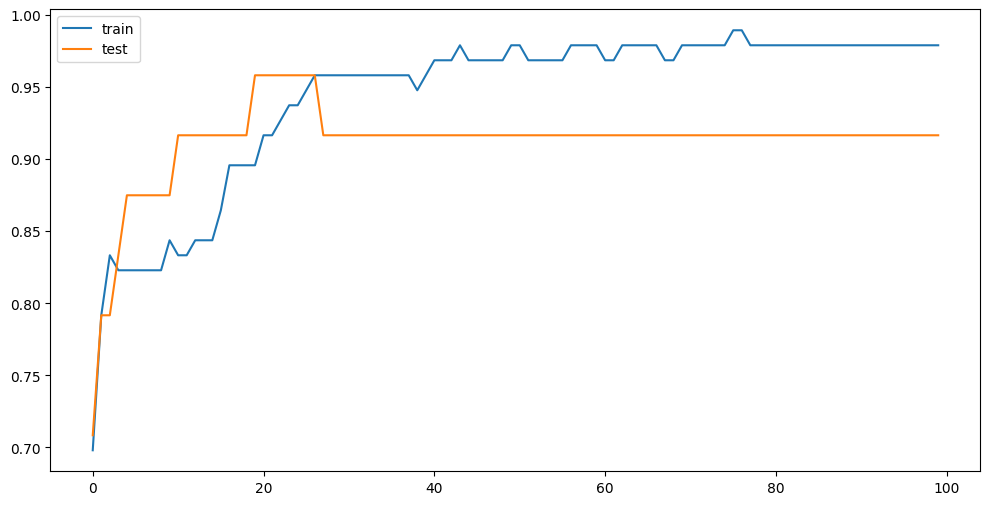

In [25]:
plt.figure(figsize=(12,6))
plt.plot(history.history['accuracy'],label='train')
plt.plot(history.history['val_accuracy'],label='test')
plt.legend()
plt.show()

### Why is Test Accuracy Decreasing while Training Accuracy is High?

This phenomenon is called **overfitting**. Here is why it happens and how to fix it:

#### 1. The Core Reason: Overfitting
* **Training Phase:** As the neural network trains over many epochs (100 in your case), it starts to memorize the specific patterns, noise, and details of the training dataset instead of learning general rules.
* **Test Phase:** Because the model has memorized the training set too well, it fails to generalize to unseen test data. Consequently, your training loss keeps going down (and training accuracy goes up), while the validation/test loss begins to increase and validation accuracy drops or plateaus.

#### 2. How to Prevent Overfitting in your Keras Model

To make your model generalize better, you can apply several regularization techniques:

* **Early Stopping:** Stop training when the validation loss stops improving. This prevents the model from training too long and memorizing the noise.
* **Dropout:** Randomly drop out neurons during training (e.g., using `Dropout(0.2)`). This forces the network to learn redundant representations and not rely on specific paths.
* **Reduce Model Complexity:** The Iris dataset is very simple (only 4 features and 150 samples). A model with `128 -> 64 -> 3` dense nodes is quite large for this task and can easily memorize the dataset. Reducing the hidden layer size will help.
* **L2 Regularization (Weight Decay):** Penalize large weights to keep the model simple.